# Choose a static or temporal query

Answer one question in two ways: **How much will each customer spend in the next 30 days?**
Use a precomputed outcome column for a static query, then let a temporal query define the outcome from timestamped transactions.
Both are regression tasks; the difference is who constructs the labels and which point in time each example represents.

This Kumo Engine module uses deterministic synthetic retail data and local files.
It validates graph and query definitions without ingesting a snapshot or training a model.
Use a prepared Linux Kumo Engine notebook environment with pandas and PyArrow installed.
No GPU is used by this module.

Read [Predictive Queries](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries) for the query workflow and [Graphs](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs) for key and time roles.



## Install

Install Kumo Engine in this notebook kernel.

In [ ]:
%pip install -q kumo-engine

## Check your notebook environment

Run this cell in the Python kernel that has Kumo Engine installed.
Import the local graph and query APIs.
Inspect the declared relationships with the graph visualization below.

In [1]:
from pathlib import Path
from tempfile import mkdtemp

import numpy as np
import pandas as pd
import kumo.engine as kumo
from kumoapi.typing import Stype



/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Set the example parameters

All editable values are here.
`OUTPUT_PARENT` is a writable local directory; the next step creates a unique subdirectory there and leaves its files for inspection.
The anchor is midnight on January 1, expressed as a timezone-naive UTC timestamp.

In [2]:
OUTPUT_PARENT = Path.cwd()
AS_OF = pd.Timestamp("2025-01-01")
HORIZON_DAYS = 30
RANDOM_SEED = 7

if HORIZON_DAYS != 30:
    raise ValueError("Keep HORIZON_DAYS=30 to match both queries in this module.")
example_dir = Path(mkdtemp(prefix="kumo-query-choice-", dir=OUTPUT_PARENT))
source_dir = example_dir / "source"
source_dir.mkdir()
print("Example files:", example_dir)

Example files: /tmp/kumo-notebook-runs/local_kumo_engine_static_and_temporal_queries/20261109T183016Z/kumo-query-choice-xdwsptf8


## Generate synthetic example data

Run the next two cells to create six customers, 75 purchases, and a prepared 30-day spending label. Three boundary purchases show which events belong to the outcome window.
You can skim this setup; the graph and query comparison starts below.


In [3]:
rng = np.random.default_rng(RANDOM_SEED)
customers = pd.DataFrame({
    "customer_id": np.arange(1, 7, dtype=np.int64),
    "signup_channel": ["web", "store", "web", "store", "web", "store"],
    "signup_region": ["north", "south", "north", "south", "north", "south"],
    "as_of": AS_OF,
})
transactions = pd.DataFrame([
    {"transaction_id": customer_id * 100 + offset,
     "customer_id": customer_id,
     "purchased_at": pd.Timestamp("2024-12-05") + pd.Timedelta(days=7 * offset),
     "amount": round(float(rng.uniform(10, 90)), 2)}
    for customer_id in customers["customer_id"]
    for offset in range(12)
])
transactions = pd.concat([
    transactions,
    pd.DataFrame({
        "transaction_id": [9001, 9002, 9003],
        "customer_id": [1, 1, 1],
        "purchased_at": [AS_OF, AS_OF + pd.Timedelta(days=30), AS_OF + pd.Timedelta(days=31)],
        "amount": [111.0, 222.0, 333.0],
    }),
], ignore_index=True)
assert customers["customer_id"].is_unique
assert transactions["transaction_id"].is_unique
assert transactions["customer_id"].isin(customers["customer_id"]).all()
print(f"Customers: {len(customers)}; transactions: {len(transactions)}")
print(transactions.head().to_string(index=False))

Customers: 6; transactions: 75
 transaction_id  customer_id purchased_at  amount
            100            1   2024-12-05   60.01
            101            1   2024-12-12   81.78
            102            1   2024-12-19   72.05
            103            1   2024-12-26   28.02
            104            1   2025-01-02   34.01


/tmp/ipykernel_1299324/1636456151.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  "purchased_at": pd.Timestamp("2024-12-05") + pd.Timedelta(days=7 * offset),
/tmp/ipykernel_1299324/1636456151.py:21: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  "purchased_at": [AS_OF, AS_OF + pd.Timedelta(days=30), AS_OF + pd.Timedelta(days=31)],


### Prepare one observed outcome per customer

For the static version, imagine that an upstream process has already calculated each customer's spend during the 30 days after `AS_OF`.
This cell performs that calculation on our synthetic history and stores it as `spend_next_30d`.
An event exactly at the anchor is excluded; an event exactly 30 days later is included.
These are historical outcomes for learning, not predictions.

The temporal version will use the purchase timestamps instead of this prepared label column.


In [4]:
in_window = (
    transactions["purchased_at"].gt(AS_OF)
    & transactions["purchased_at"].le(AS_OF + pd.Timedelta(days=HORIZON_DAYS))
)
labels = transactions.loc[in_window].groupby("customer_id")["amount"].sum()
customers["spend_next_30d"] = customers["customer_id"].map(labels).fillna(0.0)
assert transactions.loc[in_window & transactions["transaction_id"].isin([9001, 9002, 9003]), "transaction_id"].tolist() == [9002]
customers.to_parquet(source_dir / "customers.parquet", index=False)
transactions.to_parquet(source_dir / "transactions.parquet", index=False)
print(customers[["customer_id", "as_of", "spend_next_30d"]].to_string(index=False))

 customer_id      as_of  spend_next_30d
           1 2025-01-01          495.78
           2 2025-01-01          339.16
           3 2025-01-01          201.96
           4 2025-01-01          301.57
           5 2025-01-01          188.92
           6 2025-01-01          221.77


/tmp/ipykernel_1299324/3333334375.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  & transactions["purchased_at"].le(AS_OF + pd.Timedelta(days=HORIZON_DAYS))


## Connect and inspect the graph

Both graphs connect `transactions.customer_id` to `customers.customer_id`.
The static graph carries a prepared outcome and an `as_of` timestamp on the customer row.
The temporal graph excludes that outcome column so it cannot become a future-information feature.
It uses signup attributes known before the purchase history and timestamped transactions to define different prediction anchors.

Expect schema validation to succeed for both graphs.

In [5]:
files = kumo.FileConnector(root_dir=str(source_dir))
static_customers = kumo.Table.from_source_table(
    files["customers"], primary_key="customer_id", time_column="as_of",
).with_column("spend_next_30d", stype=Stype.numerical)
temporal_customers = kumo.Table.from_source_table(
    files["customers"],
    column_names=["customer_id", "signup_channel", "signup_region"],
    primary_key="customer_id",
)
transaction_table = kumo.Table.from_source_table(
    files["transactions"],
    primary_key="transaction_id", time_column="purchased_at",
).with_column("customer_id", stype=Stype.ID).with_column("amount", stype=Stype.numerical)
edges = [kumo.Edge("transactions", "customer_id", "customers")]
static_graph = kumo.Graph(
    tables={"customers": static_customers, "transactions": transaction_table},
    edges=edges,
)
temporal_graph = kumo.Graph(
    tables={"customers": temporal_customers, "transactions": transaction_table},
    edges=edges,
)
static_graph.validate()
temporal_graph.validate()
print("Both graph schemas validated")

Both graph schemas validated


### Inspect relationships

Inspect `PK`, `FK`, and `TS` roles and the relationship from transactions to customers.
Here, `purchased_at` is the event time used by the temporal query.
Hover over columns to inspect samples from the synthetic tables.


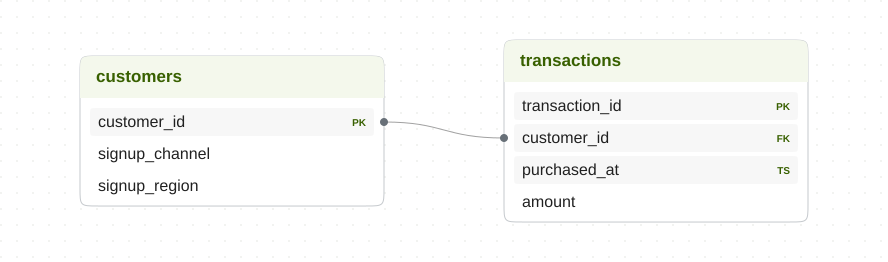

In [6]:
temporal_graph.visualize(show_cols=True, show_samples=True)

## Write the static version

Use a static query when each training example already has its outcome in a column.
Here the business question is encoded in how `spend_next_30d` was prepared; PQL names that outcome directly.
The customer row's `as_of` timestamp still matters for historical context even though the query is static.

Expect `regression`.

In [7]:
static_query = kumo.PredictiveQuery(
    static_graph,
    "PREDICT customers.spend_next_30d FOR EACH customers.customer_id",
)
static_query.validate()
print("Static task:", static_query.get_task_type())
assert static_query.get_task_type() == "regression"

Static task: regression


## Write the temporal version

Use a temporal query when timestamped events define the future outcome.
For each customer and anchor `t`, this query sums purchases after `t` through `t + 30 days`.
When training rows are later generated, Kumo calculates those labels at historical anchors.

Expect `regression` again.
`get_task_type()` identifies the prediction problem, such as regression, rather than telling you whether it is static or temporal.

In [8]:
temporal_query = kumo.PredictiveQuery(
    temporal_graph,
    "PREDICT SUM(transactions.amount, 0, 30, days) "
    "FOR EACH customers.customer_id",
)
temporal_query.validate()
print("Temporal task:", temporal_query.get_task_type())
assert temporal_query.get_task_type() == "regression"

Temporal task: regression


## Choose the formulation that matches your labels

| Your starting point | Choose | Check before training |
| --- | --- | --- |
| One prepared outcome per example | Static | The label's meaning, observation time, and split are correct. |
| Timestamped events and a future window | Temporal | The event time, horizon, anchor spacing, and available label history are correct. |

A static query can use timestamped rows and chronological splits.
A temporal query does not become classification merely because it has a window; the target expression determines the prediction problem.
For a yes/no purchase outcome, a comparison such as `COUNT(transactions.*, 0, 30, days) > 0` expresses a different target.

For temporal training, reserve enough future observations to calculate each label.
For both formulations, use only information available at the example's anchor as features.

## Export the graph and continue

Save an SVG diagram alongside the generated example files.
The synthetic input files remain in the unique example directory after the kernel stops.

To continue, create a snapshot and generate training rows using [Predictive Queries](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries), then follow [Training](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training).
See the [notebook index](../../../README.md) for the modules currently available.
You have validated definitions in this module, not trained a model or measured predictive quality.


In [9]:
graph_path = example_dir / "customer-purchases.svg"
temporal_graph.visualize(graph_path, show_cols=True)
print("Saved graph:", graph_path)
print("Ready to choose the query formulation for your own labels.")

Saved graph: /tmp/kumo-notebook-runs/local_kumo_engine_static_and_temporal_queries/20261109T183016Z/kumo-query-choice-xdwsptf8/customer-purchases.svg
Ready to choose the query formulation for your own labels.


## Continue with batch predictions

This module validates query definitions without training a model. To run inference on newly added rows, follow [the custom training-table batch example](local_kumo_engine_custom_training_table.ipynb#Batch-predictions): reserve unlabeled customers, add them after fitting, refresh the snapshot, and pass their IDs in a prediction table.
For a temporal example with explicit scoring times and observed history, see [appointment attendance](../../healthcare/notebooks/local_kumo_engine_synthetic_appointment_attendance.ipynb#Batch-predictions).
